In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


In [2]:
dados = {
    "data": [
        "2025-01-05", "2025-01-10", "2025-01-15", "2025-02-03",
        "2025-02-12", "2025-02-20", "2025-03-05", "2025-03-18",
        "2025-03-25", "2025-04-02", "2025-04-15", "2025-04-28",
        "2025-05-05", "2025-05-17", "2025-05-25", "2025-06-03",
        "2025-06-15", "2025-06-25", "2025-07-05", "2025-07-18"
    ],

    "loja": [
        "Centro", "Centro", "Shopping", "Shopping",
        "Centro", "Norte", "Norte", "Shopping",
        "Centro", "Norte", "Shopping", "Centro",
        "Norte", "Shopping", "Centro", "Norte",
        "Shopping", "Centro", "Norte", "Shopping"
    ],

    "produto": [
        "Notebook", "Mouse", "Teclado", "Monitor",
        "Notebook", "Mouse", "Celular", "Teclado",
        "Monitor", "Notebook", "Celular", "Mouse",
        "Teclado", "Notebook", "Monitor", "Celular",
        "Mouse", "Notebook", "Teclado", "Monitor"
    ],

    "quantidade": [
        2, 10, 5, 3, 1, 15, 4, 8, 6, 2,
        3, 20, 10, 2, 5, 4, 18, 3, 12, 4
    ],

    "preco_unitario": [
        3500, 80, 150, 1200, 3500, 80, 2500, 150,
        1200, 3500, 2500, 80, 150, 3500, 1200,
        2500, 80, 3500, 150, 1200
    ]
}

df = pd.DataFrame(dados)

df.head()


,data,loja,produto,quantidade,preco_unitario
0,2025-01-05,Centro,Notebook,2,3500
1,2025-01-10,Centro,Mouse,10,80
2,2025-01-15,Shopping,Teclado,5,150
3,2025-02-03,Shopping,Monitor,3,1200
4,2025-02-12,Centro,Notebook,1,3500


In [3]:
df["data"] = pd.to_datetime(df["data"])

df.info()




<class 'pandas.DataFrame'>
RangeIndex: 20 entries, 0 to 19
Data columns (total 5 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   data            20 non-null     datetime64[us]
 1   loja            20 non-null     str           
 2   produto         20 non-null     str           
 3   quantidade      20 non-null     int64         
 4   preco_unitario  20 non-null     int64         
dtypes: datetime64[us](1), int64(2), str(2)
memory usage: 932.0 bytes


In [4]:
df["faturamento"] = df["quantidade"] * df["preco_unitario"]

df.head()


,data,loja,produto,quantidade,preco_unitario,faturamento
0,2025-01-05,Centro,Notebook,2,3500,7000
1,2025-01-10,Centro,Mouse,10,80,800
2,2025-01-15,Shopping,Teclado,5,150,750
3,2025-02-03,Shopping,Monitor,3,1200,3600
4,2025-02-12,Centro,Notebook,1,3500,3500


In [5]:
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 20 entries, 0 to 19
Data columns (total 6 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   data            20 non-null     datetime64[us]
 1   loja            20 non-null     str           
 2   produto         20 non-null     str           
 3   quantidade      20 non-null     int64         
 4   preco_unitario  20 non-null     int64         
 5   faturamento     20 non-null     int64         
dtypes: datetime64[us](1), int64(3), str(2)
memory usage: 1.1 KB


In [6]:
df.isnull().sum()


data              0
loja              0
produto           0
quantidade        0
preco_unitario    0
faturamento       0
dtype: int64

In [7]:
df.describe()


,data,quantidade,preco_unitario,faturamento
count,20,20.000000,20.00000,20.000000
mean,2025-04-09 07:12:00,6.850000,1536.00000,4719.500000
min,2025-01-05 00:00:00,1.000000,80.00000,750.000000
25%,2025-02-18 00:00:00,3.000000,150.00000,1485.000000
50%,2025-04-08 12:00:00,4.500000,1200.00000,4200.000000
75%,2025-05-27 06:00:00,10.000000,2750.00000,7050.000000
max,2025-07-18 00:00:00,20.000000,3500.00000,10500.000000
std,NaN,5.584518,1426.98947,3389.787255


In [8]:
df["quantidade"] = df["quantidade"].fillna(df["quantidade"].mean())

df["preco_unitario"] = df["preco_unitario"].fillna(
    df["preco_unitario"].mean()
)

df["faturamento"] = df["quantidade"] * df["preco_unitario"]


In [9]:
faturamento_loja = (
    df.groupby("loja")["faturamento"]
    .sum()
    .sort_values(ascending=False)
)

faturamento_loja


loja
Centro      36600
Norte       31500
Shopping    26290
Name: faturamento, dtype: int64

In [10]:
ticket_medio = (
    df.groupby("loja")["faturamento"]
    .mean()
    .sort_values(ascending=False)
)

ticket_medio


loja
Norte       5250.000000
Centro      5228.571429
Shopping    3755.714286
Name: faturamento, dtype: float64

In [11]:
produtos_mais_vendidos = (
    df.groupby("produto")["quantidade"]
    .sum()
    .sort_values(ascending=False)
    .head(5)
)

produtos_mais_vendidos


produto
Mouse       63
Teclado     35
Monitor     18
Celular     11
Notebook    10
Name: quantidade, dtype: int64

In [12]:
df["mes"] = df["data"].dt.month

df.head()


,data,loja,produto,quantidade,preco_unitario,faturamento,mes
0,2025-01-05,Centro,Notebook,2,3500,7000,1
1,2025-01-10,Centro,Mouse,10,80,800,1
2,2025-01-15,Shopping,Teclado,5,150,750,1
3,2025-02-03,Shopping,Monitor,3,1200,3600,2
4,2025-02-12,Centro,Notebook,1,3500,3500,2


In [13]:
faturamento_mensal = (
    df.groupby(df["data"].dt.to_period("M"))["faturamento"]
    .sum()
)

faturamento_mensal


data
2025-01     8550
2025-02     8300
2025-03    18400
2025-04    16100
2025-05    14500
2025-06    21940
2025-07     6600
Freq: M, Name: faturamento, dtype: int64

In [15]:
print(
    "Mês com maior faturamento:",
    maior_mes.strftime("%m/%Y")
)

print(
    "Mês com menor faturamento:",
    menor_mes.strftime("%m/%Y")
)


Mês com maior faturamento: 06/2025
Mês com menor faturamento: 07/2025


FileNotFoundError: [Errno 2] No such file or directory: 'graficos/faturamento_por_loja.png'

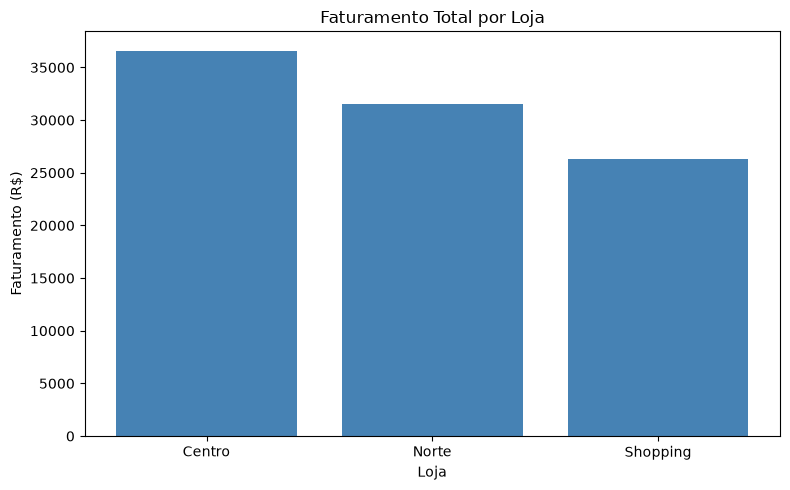

In [19]:
plt.figure(figsize=(8, 5))

plt.bar(
    faturamento_loja.index,
    faturamento_loja.values,
    color="steelblue"
)

plt.title("Faturamento Total por Loja")
plt.xlabel("Loja")
plt.ylabel("Faturamento (R$)")

plt.tight_layout()

plt.savefig("graficos/faturamento_por_loja.png")

plt.show()


In [20]:
print(faturamento_mensal)


data
2025-01     8550
2025-02     8300
2025-03    18400
2025-04    16100
2025-05    14500
2025-06    21940
2025-07     6600
Freq: M, Name: faturamento, dtype: int64


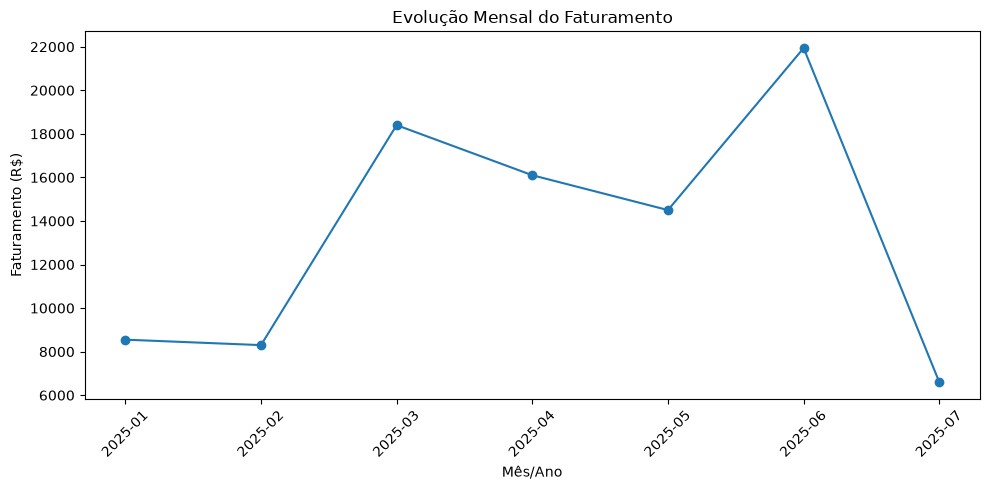

In [26]:
plt.figure(figsize=(10, 5))

plt.plot(
    faturamento_mensal.index.astype(str),
    faturamento_mensal.values,
    marker="o"
)

plt.title("Evolução Mensal do Faturamento")
plt.xlabel("Mês/Ano")
plt.ylabel("Faturamento (R$)")

plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig("graficos/evolucao_mensal.png")

plt.show()


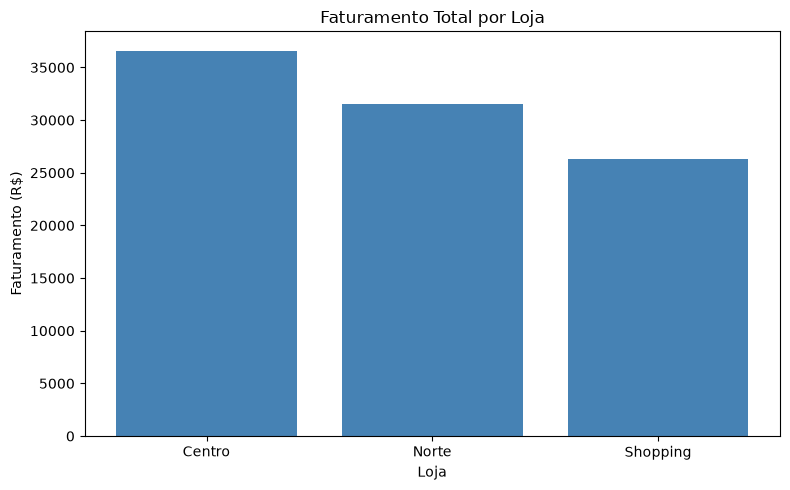

In [27]:
plt.figure(figsize=(8, 5))

plt.bar(
    faturamento_loja.index,
    faturamento_loja.values,
    color="steelblue"
)

plt.title("Faturamento Total por Loja")
plt.xlabel("Loja")
plt.ylabel("Faturamento (R$)")

plt.tight_layout()

plt.savefig("graficos/faturamento_por_loja.png")

plt.show()


In [28]:
regioes = {
    "Centro": "Central",
    "Shopping": "Sul",
    "Norte": "Norte"
}

df["regiao"] = df["loja"].map(regioes)

df.head()


,data,loja,produto,quantidade,preco_unitario,faturamento,mes,regiao
0,2025-01-05,Centro,Notebook,2,3500,7000,1,Central
1,2025-01-10,Centro,Mouse,10,80,800,1,Central
2,2025-01-15,Shopping,Teclado,5,150,750,1,Sul
3,2025-02-03,Shopping,Monitor,3,1200,3600,2,Sul
4,2025-02-12,Centro,Notebook,1,3500,3500,2,Central


In [25]:
import os

os.makedirs("graficos", exist_ok=True)

print("Pasta graficos criada!")


Pasta graficos criada!


In [29]:
faturamento_regiao = (
    df.groupby("regiao")["faturamento"]
    .sum()
)

faturamento_regiao


regiao
Central    36600
Norte      31500
Sul        26290
Name: faturamento, dtype: int64

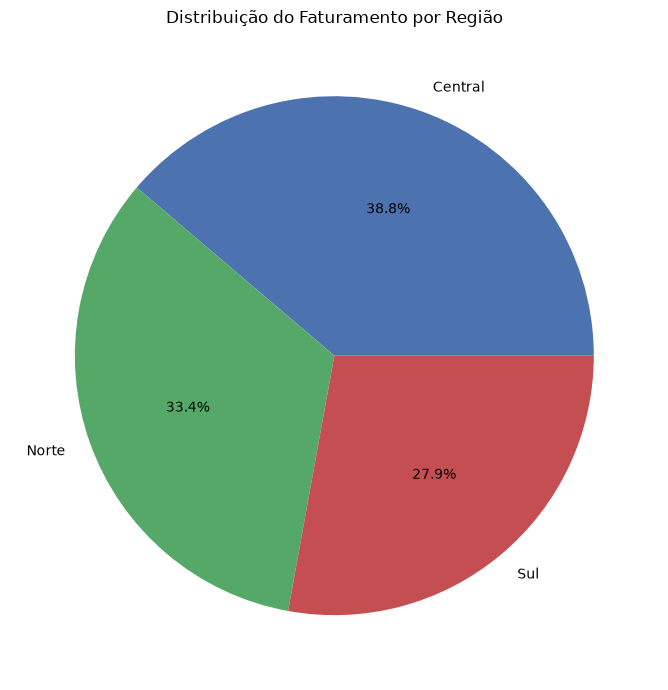

In [30]:
plt.figure(figsize=(7, 7))

plt.pie(
    faturamento_regiao.values,
    labels=faturamento_regiao.index,
    autopct="%1.1f%%",
    colors=["#4C72B0", "#55A868", "#C44E52"]
)

plt.title("Distribuição do Faturamento por Região")

plt.tight_layout()

plt.savefig("graficos/faturamento_por_regiao.png")

plt.show()


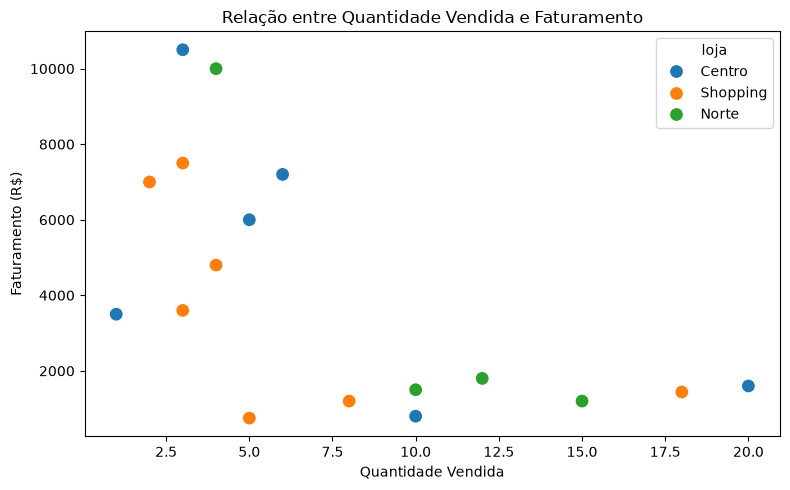

In [31]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="quantidade",
    y="faturamento",
    hue="loja",
    s=100
)

plt.title("Relação entre Quantidade Vendida e Faturamento")
plt.xlabel("Quantidade Vendida")
plt.ylabel("Faturamento (R$)")

plt.tight_layout()

plt.savefig("graficos/quantidade_vs_faturamento.png")

plt.show()


In [32]:
categorias = {
    "Notebook": "Informática",
    "Mouse": "Informática",
    "Teclado": "Informática",
    "Monitor": "Informática",
    "Celular": "Eletrônicos"
}

df["categoria"] = df["produto"].map(categorias)

df.head()


,data,loja,produto,quantidade,preco_unitario,faturamento,mes,regiao,categoria
0,2025-01-05,Centro,Notebook,2,3500,7000,1,Central,Informática
1,2025-01-10,Centro,Mouse,10,80,800,1,Central,Informática
2,2025-01-15,Shopping,Teclado,5,150,750,1,Sul,Informática
3,2025-02-03,Shopping,Monitor,3,1200,3600,2,Sul,Informática
4,2025-02-12,Centro,Notebook,1,3500,3500,2,Central,Informática


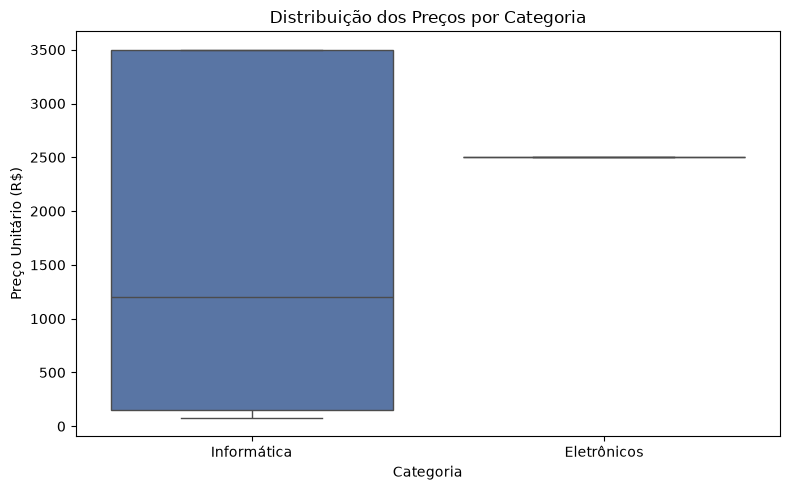

In [33]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="categoria",
    y="preco_unitario",
    hue="categoria",
    palette="deep",
    legend=False
)

plt.title("Distribuição dos Preços por Categoria")
plt.xlabel("Categoria")
plt.ylabel("Preço Unitário (R$)")

plt.tight_layout()

plt.savefig("graficos/precos_por_categoria.png")

plt.show()


In [34]:
correlacao = df.select_dtypes(include="number").corr()

correlacao


,quantidade,preco_unitario,faturamento,mes
quantidade,1.000000,-0.766399,-0.639468,0.135838
preco_unitario,-0.766399,1.000000,0.798394,0.019886
faturamento,-0.639468,0.798394,1.000000,0.248387
mes,0.135838,0.019886,0.248387,1.000000


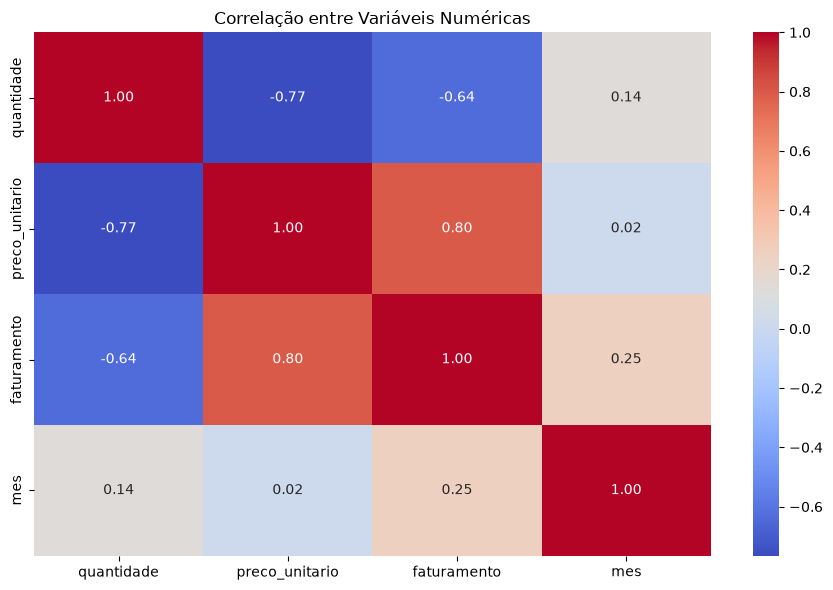

In [35]:
plt.figure(figsize=(9, 6))

sns.heatmap(
    correlacao,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlação entre Variáveis Numéricas")

plt.tight_layout()

plt.savefig("graficos/heatmap_correlacao.png")

plt.show()


In [36]:
sns.set_style("whitegrid")
sns.set_palette("deep")


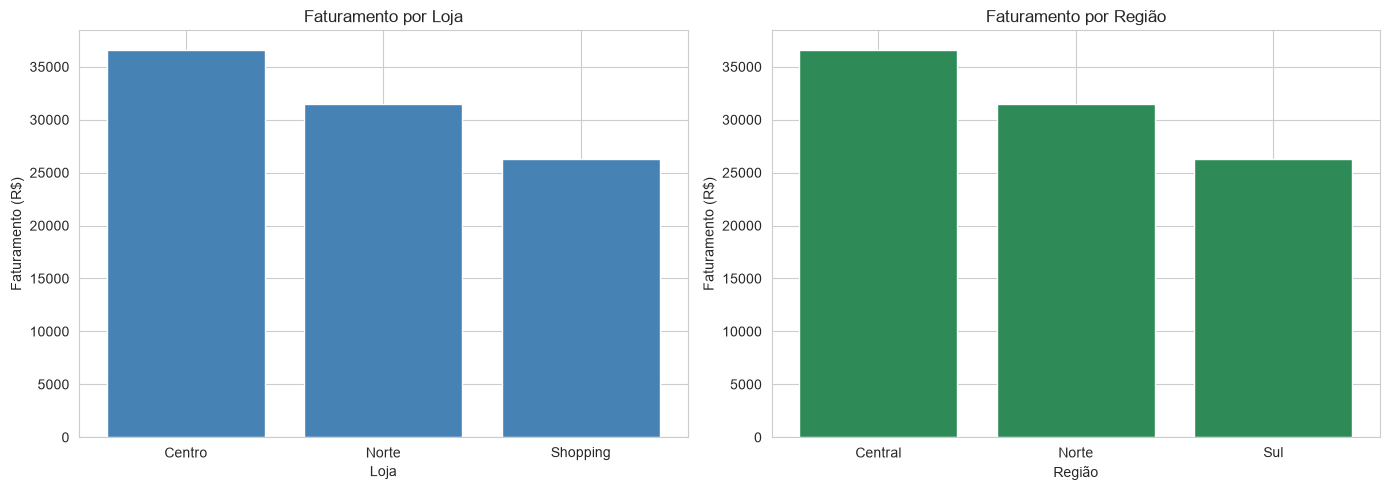

In [37]:
plt.figure(figsize=(14, 5))

# Primeiro gráfico
plt.subplot(1, 2, 1)

plt.bar(
    faturamento_loja.index,
    faturamento_loja.values,
    color="steelblue"
)

plt.title("Faturamento por Loja")
plt.xlabel("Loja")
plt.ylabel("Faturamento (R$)")


# Segundo gráfico
plt.subplot(1, 2, 2)

plt.bar(
    faturamento_regiao.index,
    faturamento_regiao.values,
    color="seagreen"
)

plt.title("Faturamento por Região")
plt.xlabel("Região")
plt.ylabel("Faturamento (R$)")

plt.tight_layout()

plt.savefig("graficos/comparacao_loja_regiao.png")

plt.show()


In [38]:
resumo = {
    "Indicador": [
        "Maior faturamento mensal",
        "Menor faturamento mensal",
        "Loja com maior faturamento",
        "Produto mais vendido"
    ],
    
    "Resultado": [
        str(maior_mes),
        str(menor_mes),
        faturamento_loja.idxmax(),
        produtos_mais_vendidos.idxmax()
    ]
}

resumo_df = pd.DataFrame(resumo)

resumo_df


,Indicador,Resultado
0,Maior faturamento mensal,2025-06
1,Menor faturamento mensal,2025-07
2,Loja com maior faturamento,Centro
3,Produto mais vendido,Mouse


In [39]:
resumo_df.to_csv(
    "resumo_analitico.csv",
    index=False
)

print("Resumo salvo com sucesso!")


Resumo salvo com sucesso!
